# 03 · Assemble sections, CS+AMC groups and chunks

* **Stitching**: the regions of a section are joined; a table that continues on the next page becomes one table (repeated header dropped); a sentence cut by the page break is re-joined.
* **Nesting** is rebuilt deterministically from the markers, `(a)` → `(1)` → `(i)` → `(A)` (2 spaces per level), so every page uses the same indentation.
* **Outputs** in `data/`:
  * `sections.jsonl`: one record per CS-E / AMC / appendix (full text, never split)
  * `groups.jsonl`: one record per CS-E: the CS text followed by all its AMCs, for pulling a whole group back together
  * `chunks.jsonl`: retrieval units. A section is split **only** if it is longer than `MAX_TOKENS`, and only at its own top-level `(a)/(b)/…` paragraphs or `###` sub-headings (deeper levels if still too long). Every chunk keeps `section_id`, `group_id`, `kind` (`cs`/`amc`/`appendix`/`amc_general`) and a breadcrumb.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)  # all paths below are relative to the repo root
from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
PDF = ROOT / "cs-e_amendment_9.pdf"   # header/footer already cropped
DATA = ROOT / "data"

In [2]:
import json
import pandas as pd
from csparse.segment import load_sections
from csparse.vlm import load_cache
from csparse.merge import Corpus, assemble_groups, assemble_sections, check_outputs, default_counter, make_chunks, write_jsonl

MAX_TOKENS = 1500           # chunk size limit (cl100k tokens); tune for your embedding model
count = default_counter()    # swap in your embedding model's tokenizer if you like

sections = load_sections(DATA / "sections.json")
cache = load_cache(DATA / "vlm_cache", sections)
missing = [sid for sid, recs in cache.items() if any(r is None for r in recs)]
print(len(sections), "sections;", len(missing), "with missing regions", missing[:10])

175 sections; 0 with missing regions []


In [3]:
sec_recs = assemble_sections(sections, cache)
groups = assemble_groups(sec_recs)
chunks = make_chunks(sec_recs, max_tokens=MAX_TOKENS, count=count)

write_jsonl(sec_recs, DATA / "sections.jsonl")
write_jsonl(groups, DATA / "groups.jsonl")
write_jsonl(chunks, DATA / "chunks.jsonl")
print(f"{len(sec_recs)} sections, {len(groups)} groups, {len(chunks)} chunks written to {DATA}")

175 sections, 92 groups, 252 chunks written to /home/goksu/projects/ikincitik/data


### Checks (every list must be empty)
* `amdt_left`: `[Amdt …]` notes still in the text
* `header_leaks`: page header/footer text that slipped in
* `chunks_not_from_own_section`: chunks containing a line that is not in their own section, i.e. a boundary violation

In [4]:
checks = check_outputs(sec_recs, chunks)
for k, v in checks.items():
    print(f"{k:28} {len(v):3}  {v[:8]}")

amdt_left                      0  []
header_leaks                   0  []
empty_sections                 0  []
incomplete_sections            0  []
chunks_not_from_own_section    0  []


{'amc': 144, 'cs': 106, 'amc_general': 1, 'appendix': 1}
sections split into >1 chunk: 18


,chunk_id,n_tokens,breadcrumb,page_start,page_end
95,AMC E 510#03,1499,SUBPART D > AMC E 510 Safety Analysis > (3) > ...,86,94
18,CS-E 50,1489,SUBPART A > CS-E 50 Engine Control System,35,37
31,AMC E 80#03,1489,SUBPART A > AMC E 80 Equipment > (2) > (a),46,52
205,CS-E 800#02,1483,SUBPART E > CS-E 800 Bird Strike and Ingestion...,218,225
206,CS-E 800#03,1463,SUBPART E > CS-E 800 Bird Strike and Ingestion...,218,225
168,AMC E 740(c)(4)#04,1457,SUBPART E > AMC E 740(c)(4) Alternate Enduranc...,156,177
132,AMC E 650#02,1452,SUBPART E > AMC E 650 Vibration Surveys > (4)–(5),124,134
187,AMC E 780#07,1451,SUBPART E > AMC E 780 Icing Conditions > (2) >...,183,200
200,AMC E 790(a)(2)#06,1449,SUBPART E > AMC E 790(a)(2) Rain and Hail Inge...,202,216
154,CS-E 740#02,1447,SUBPART E > CS-E 740 Endurance Tests > (c) > (...,142,155


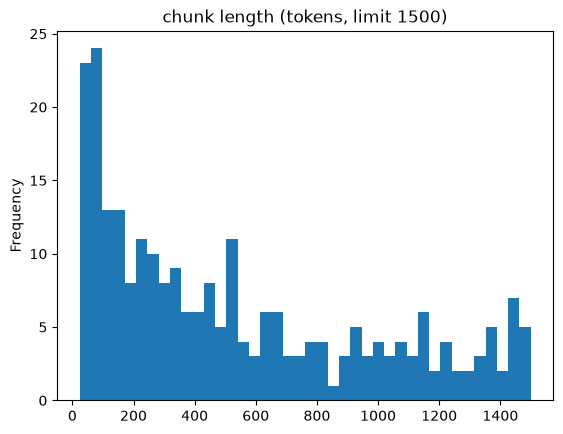

In [5]:
cdf = pd.DataFrame(chunks)
print(cdf.kind.value_counts().to_dict())
print(f"sections split into >1 chunk: {(cdf.part_count > 1).groupby(cdf.section_id).any().sum()}")
ax = cdf.n_tokens.plot.hist(bins=40, title=f"chunk length (tokens, limit {MAX_TOKENS})")
cdf.sort_values("n_tokens", ascending=False)[["chunk_id", "n_tokens", "breadcrumb", "page_start", "page_end"]].head(10)

### Spot checks

In [6]:
corpus = Corpus(DATA)
print(corpus.get_section("CS-E 15")["text"][:3000])

## CS-E 15 Terminology

(a) The terminology of this CS-E 15 must be used in conjunction with the issue of CS-Definitions current at the date of issue of this CS-E. Where used in CS-E, the terms defined in this paragraph and in CS-Definitions are identified by initial capital letters.
(b) All Engines
  - **Extremely Remote**: means unlikely to occur when considering the total operational life of a number of aircraft of the type in which the Engine is installed, but nevertheless, has to be regarded as being possible. Where numerical values are used this may normally be interpreted as a probability in the range 10^-7 to 10^-9 per Engine flight hour.
  - **Reasonably Probable**: means unlikely to occur often during the operation of each aircraft of the type but which may occur several times during the total operational life of each aircraft of the types in which the Engine may be installed. Where numerical values are used this may normally be interpreted as a probability in the range 10^-3

In [7]:
print(corpus.get_section("AMC E 30")["text"][:2500])

## AMC E 30 Assumptions

The details required by CS-E 30 concerning assumptions should normally include information on, at least, the items listed in Table 1.

TABLE 1

| Specifications/References | Assumptions |
|---|---|
| **ALL ENGINES** |  |
| Interfaces CS-E 20 | Applicable aircraft specifications. Flight and ground loads. Aircraft components and equipment not included in the Engine definition. Attitudes. Negative g duration. Physical and functional interfaces with the aircraft Mount flexibility. |
| Engine Control System CS-E 50 | Type of aircraft installation. Conditions on the interfaces with the aircraft or the Propeller Environmental Conditions. |
| Instrumentation CS-E 60 | Instrumentation required and statement of accuracy. For engines with 30-Second / 2-Minute OEI ratings, conditions imposed on the usage recording system. |
| Strength CS-E 100 CS-E 520, CS-E 640 | Ultimate and limit loads; – out-of-balance loads, – operating envelope. |
| Fire precautions CS-E 130 | Relian

A long section, split at its own paragraphs:

In [8]:
for c in cdf[cdf.section_id == "CS-E 740"].itertuples():
    print(f"{c.chunk_id:14} {c.n_tokens:5}  {c.breadcrumb}")
print()
first = cdf[cdf.section_id == "CS-E 740"].chunk_id.iloc[0]
print(corpus.chunks[first]["text"][:1200])

CS-E 740#01      458  SUBPART E > CS-E 740 Endurance Tests > (a)–(b)
CS-E 740#02     1447  SUBPART E > CS-E 740 Endurance Tests > (c) > (1)–(2)
CS-E 740#03      799  SUBPART E > CS-E 740 Endurance Tests > (c) > (3)
CS-E 740#04      713  SUBPART E > CS-E 740 Endurance Tests > (c) > (4) > (i)–(iii)
CS-E 740#05     1392  SUBPART E > CS-E 740 Endurance Tests > (c) > (4) > (iv)–(viii)
CS-E 740#06      530  SUBPART E > CS-E 740 Endurance Tests > (d)–(e)
CS-E 740#07      522  SUBPART E > CS-E 740 Endurance Tests > (f) > (1)–(3)
CS-E 740#08     1046  SUBPART E > CS-E 740 Endurance Tests > (f) > (4)
CS-E 740#09      652  SUBPART E > CS-E 740 Endurance Tests > (f) > (5)
CS-E 740#10      708  SUBPART E > CS-E 740 Endurance Tests > (g)–(i)

CS-E 740 Endurance Tests — (a)–(b) (part 1/10)

(a) The specifications of CS-E 740 must be varied and supplemented as necessary to comply with CS-E 690(a), CS-E 750 and CS-E 890.

(b) (1) The test must be performed in the order defined in the appropriate schedu

### Pulling a group back together
A retrieval hit on any chunk can be expanded to its full section or to its whole CS-E + AMC group.

In [9]:
g = corpus.get_group("CS-E 20")
print(g["section_ids"], g["page_start"], g["page_end"])
print([s["section_id"] for s in corpus.group_sections("CS-E 20", kind="amc")])
hit = cdf[cdf.section_id == "AMC E 20(f)"].chunk_id.iloc[0]   # pretend the retriever returned this chunk
print(corpus.expand(hit, to="section")["title"])
print(corpus.expand(hit, to="group")["text"][:1500])

['CS-E 20', 'AMC E 20', 'AMC E 20(f)'] 19 22
['AMC E 20', 'AMC E 20(f)']
AMC E 20(f) Power Assurance Data for Engines with One or More OEI Power Ratings
## CS-E 20 Engine Configuration and Interfaces

(See AMC E 20)

(a) The list of all the parts and equipment, including references to the relevant drawings, which defines the proposed type design of the Engine, must be established.

(b) The aircraft certification specification code which is assumed to be applicable to the intended installation of the Engine must be identified under CS-E 30.

(c) The aircraft parts and equipment that may be mounted on, or driven by, the Engine, which are not part of the declared Engine configuration and therefore are not covered by the Engine Type Certificate must be identified.

(d) Manuals must be provided containing instructions for installing and operating the Engine. These instructions must contain a definition of the physical and functional interfaces with the aircraft and aircraft equipment. They 